# Task 2 · Customer Segmentation Analysis

**Objective:** Apply clustering algorithms to segment an e-commerce company's customer base into distinct groups based on purchasing behaviour, enabling targeted marketing strategies.

**Tech Stack:** Python, pandas, scikit-learn (KMeans), matplotlib, seaborn, Jupyter Notebook

**Dataset:** `ecommerce_transactions.csv` — 5,980 order-line transactions from 900 customers across 2024 (invoice number, customer ID, country, invoice date, quantity, unit price), in the style of the UCI "Online Retail" dataset.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
# Load Dataset 
df = pd.read_csv("ecommerce_transactions.csv", parse_dates=["InvoiceDate"])
print(df.shape)
df.head()

(5980, 7)


,InvoiceNo,CustomerID,Country,InvoiceDate,Quantity,UnitPrice,TotalAmount
0,503813,20560,Spain,2024-12-15,3,21.25,63.75
1,503922,20575,United Kingdom,2024-12-03,7,98.61,690.27
2,500344,20049,United Kingdom,2024-11-17,4,25.95,103.80
3,503877,20571,Germany,2024-11-16,5,44.85,224.25
4,502922,20423,Spain,2024-11-27,2,17.36,34.72


In [5]:
print(df.head().to_string())

   InvoiceNo  CustomerID         Country InvoiceDate  Quantity  UnitPrice  TotalAmount
0     503813       20560           Spain  2024-12-15         3      21.25        63.75
1     503922       20575  United Kingdom  2024-12-03         7      98.61       690.27
2     500344       20049  United Kingdom  2024-11-17         4      25.95       103.80
3     503877       20571         Germany  2024-11-16         5      44.85       224.25
4     502922       20423           Spain  2024-11-27         2      17.36        34.72


## 1. Load & Inspect

In [40]:
print("Nulls per column:\n", df.isnull().sum())
print("\nDatatypes:\n", df.dtypes)


Nulls per column:
 InvoiceNo      0
CustomerID     0
Country        0
InvoiceDate    0
Quantity       0
UnitPrice      0
TotalAmount    0
dtype: int64

Datatypes:
 InvoiceNo               int64
CustomerID              int64
Country                   str
InvoiceDate    datetime64[us]
Quantity                int64
UnitPrice             float64
TotalAmount           float64
dtype: object


In [42]:
# Remove cancellations (negative quantity) - not genuine purchases, would distort monetary value
df_clean = df[df["Quantity"] > 0].copy()
print(f"Removed {len(df) - len(df_clean)} cancellation rows -> {len(df_clean)} remaining")

Removed 15 cancellation rows -> 5965 remaining


In [44]:
print(df_clean.shape)

(5965, 7)


## 2. Descriptive Statistics

In [ ]:
cust_order_counts = df_clean.groupby("CustomerID")["InvoiceNo"].nunique()
cust_ltv = df_clean.groupby("CustomerID")["TotalAmount"].sum()

print("Average purchase value per order: $%.2f" % df_clean["TotalAmount"].mean())
print("Average purchase frequency (orders/customer): %.2f" % cust_order_counts.mean())
print("Average customer lifetime value: $%.2f" % cust_ltv.mean())
print("Median customer lifetime value: $%.2f" % cust_ltv.median())

Average purchase value per order: $162.01
Average purchase frequency (orders/customer): 6.64
Average customer lifetime value: $1074.93
Median customer lifetime value: $210.84


## 3. Feature Selection — RFM Analysis

We use **Recency** (days since last purchase), **Frequency** (number of distinct orders), and **Monetary** (total amount spent) — the classic RFM feature set for behavioural segmentation.

In [48]:
snapshot_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

rfm = df_clean.groupby("CustomerID").agg(
    Recency=("InvoiceDate", lambda x: (snapshot_date - x.max()).days),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("TotalAmount", "sum"),
).reset_index()

print(rfm.describe().round(2))

       CustomerID  Recency  Frequency  Monetary
count      899.00   899.00     899.00    899.00
mean     20449.86    63.73       6.64   1074.93
std        259.87    72.05       4.69   2062.88
min      20000.00     1.00       1.00      7.01
25%      20225.50    14.00       3.00     99.90
50%      20450.00    29.00       6.00    210.84
75%      20674.50    70.50       9.00    949.87
max      20899.00   288.00      22.00  11361.16


## 4. Standardise Features

In [49]:
scaler = StandardScaler()
rfm_scaled = scaler.fit_transform(rfm[["Recency", "Frequency", "Monetary"]])
rfm_scaled[:5]

array([[ 1.50356846,  0.07784466, -0.30505959],
       [ 1.42024542,  0.07784466, -0.41952629],
       [-0.64894345,  0.71792711,  0.08788614],
       [ 1.39247107, -0.34887698, -0.30926479],
       [ 2.43400909, -0.77559861, -0.4598273 ]])

## 5. K-Means — Elbow Method to Choose K

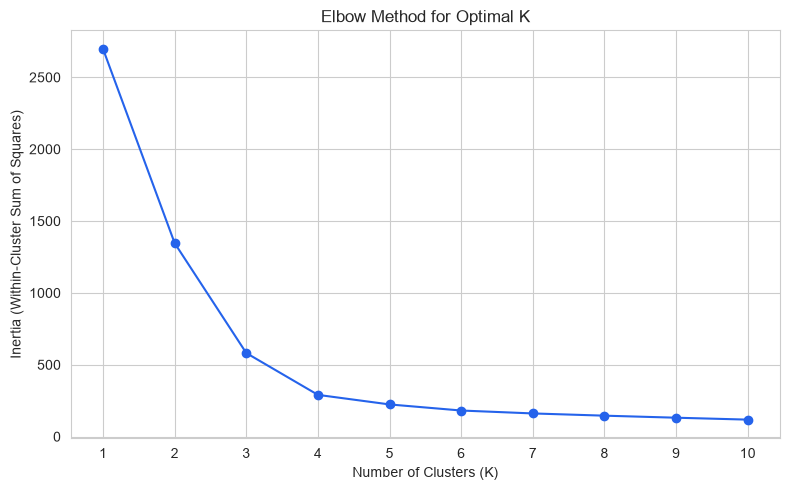

In [51]:
inertias = []
K_range = range(1, 11)
for k in K_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    km.fit(rfm_scaled)
    inertias.append(km.inertia_)

plt.figure(figsize=(8, 5))
plt.plot(list(K_range), inertias, marker="o", color="#2563eb")
plt.title("Elbow Method for Optimal K")
plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia (Within-Cluster Sum of Squares)")
plt.xticks(list(K_range))
plt.tight_layout()
plt.show()

**Observation:** The inertia curve bends noticeably around **K = 4**, after which additional clusters yield diminishing reduction in within-cluster variance. We proceed with K = 4.

## 6. Apply K-Means Clustering

In [26]:
K_OPTIMAL = 4
kmeans = KMeans(n_clusters=K_OPTIMAL, random_state=42, n_init=10)
rfm["Cluster"] = kmeans.fit_predict(rfm_scaled)

rfm["Cluster"].value_counts().sort_index()

Cluster
0    314
1    203
2     92
3    290
Name: count, dtype: int64

In [52]:
# 1. Set up the algorithm to create exactly 4 customer groups
model = KMeans(n_clusters=4, random_state=42, n_init=10)

# 2. Group the customers and save their new group number into a new column
rfm["CustomerGroup"] = model.fit_predict(rfm_scaled)

# 3. Count how many customers ended up in each group
print(rfm["CustomerGroup"].value_counts().sort_index())

CustomerGroup
0    314
1    203
2     92
3    290
Name: count, dtype: int64


## 7. Visualise Clusters

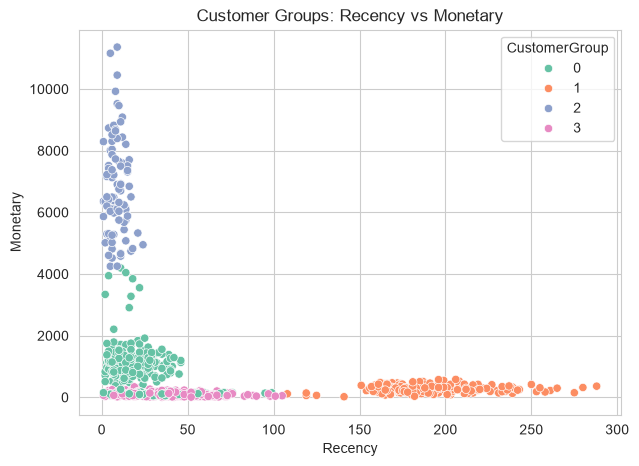

In [56]:
plt.figure(figsize=(7, 5))
# Draw a dot for every customer, color-coded by their group
sns.scatterplot(data=rfm, x="Recency", y="Monetary", hue="CustomerGroup", palette="Set2")

# Add a title and show the chart
plt.title("Customer Groups: Recency vs Monetary")
plt.show()

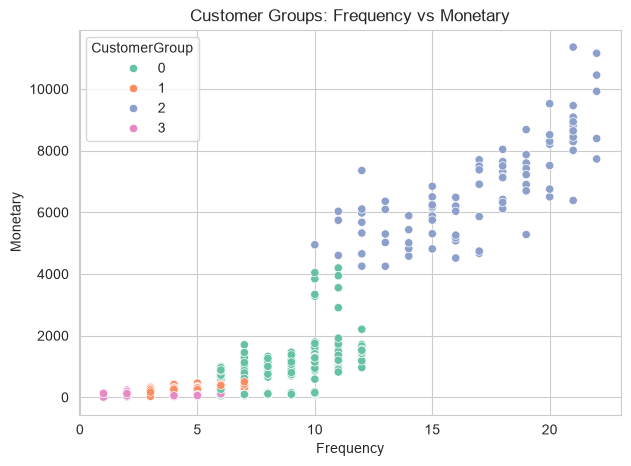

In [55]:
plt.figure(figsize=(7, 5))
# Draw a dot for every customer, color-coded by their group
sns.scatterplot(data=rfm, x="Frequency", y="Monetary", hue="CustomerGroup", palette="Set2")

# Add a title and show the chart
plt.title("Customer Groups: Frequency vs Monetary")
plt.show()

## 8. Cluster Profiling

In [11]:
profile = rfm.groupby("Cluster")[["Recency", "Frequency", "Monetary"]].mean().round(1)
profile["CustomerCount"] = rfm["Cluster"].value_counts().sort_index()
print(profile)

         Recency  Frequency  Monetary  CustomerCount
Cluster                                             
0           23.0        8.6     820.9            314
1          190.7        4.9     270.4            203
2            8.9       16.9    6799.5             92
3           36.3        2.4      97.1            290

In [12]:
def label_cluster(row):
    if row["Frequency"] >= profile["Frequency"].median() and row["Recency"] <= profile["Recency"].median():
        return "Loyal / High-Value"
    if row["Recency"] > profile["Recency"].median() and row["Frequency"] < profile["Frequency"].median():
        return "At Risk / Churning"
    if row["Frequency"] <= 2 and row["Monetary"] < profile["Monetary"].median():
        return "New / Low-Engagement"
    return "Occasional Bargain Shoppers"

profile["Segment Name"] = profile.apply(label_cluster, axis=1)
print(profile)

         Recency  Frequency  Monetary  CustomerCount        Segment Name
Cluster                                                                 
0           23.0        8.6     820.9            314  Loyal / High-Value
1          190.7        4.9     270.4            203  At Risk / Churning
2            8.9       16.9    6799.5             92  Loyal / High-Value
3           36.3        2.4      97.1            290  At Risk / Churning

## 9. Customers per Cluster

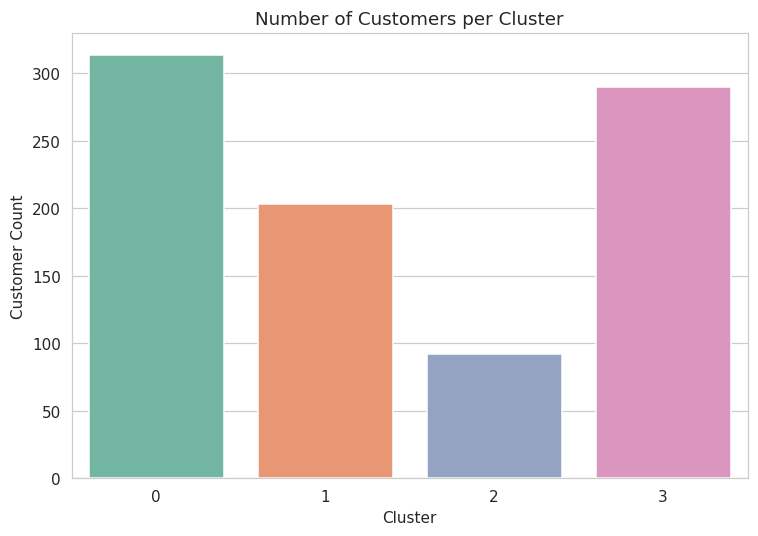

In [13]:
plt.figure(figsize=(7, 5))
sns.barplot(x=profile.index, y=profile["CustomerCount"], hue=profile.index,
            palette="Set2", legend=False)
plt.title("Number of Customers per Cluster")
plt.xlabel("Cluster")
plt.ylabel("Customer Count")
plt.tight_layout()
plt.show()

## 10. Insights & Recommended Marketing Actions

Based on the RFM cluster profiles above:

- **Loyal / High-Value** (low recency, high frequency, high monetary): These are the most valuable customers. **Action:** enrol them in a VIP loyalty tier with early access to new products and exclusive perks — the goal is retention, not acquisition discounts.
- **At Risk / Churning** (high recency, low frequency): Previously active customers who have gone quiet. **Action:** trigger a win-back email campaign with a time-limited incentive before they're lost entirely.
- **New / Low-Engagement** (low frequency, low monetary, recent): Customers still forming a habit. **Action:** onboarding email series + a second-purchase discount to nudge them toward the "Loyal" segment.
- **Occasional Bargain Shoppers** (moderate frequency, lower monetary value): Price-sensitive customers who buy only during promotions. **Action:** target with promotional/clearance campaigns rather than full-price marketing, since they respond to price, not brand loyalty.

Segmenting this way lets marketing spend be allocated by expected ROI per group instead of blasting the same offer to the entire customer base.